# Module 7 — Task 1: Predict the next price move from the order book

**The Head of Trading's question (brief, verbatim):**
> NovaFin's trading desk executes large equity orders in the market. The Head of Trading asks: **Can ML use limit-order-book information to predict short-horizon price movements and improve order execution?**

**Task 1 (brief, verbatim):**
> **ML Task 1 — Short-Horizon Direction Prediction.** Target: Price_Move_Class with: UP, DOWN, NO_MOVE. Note: the provided dataset (nova_hft_orderbook.csv) labels this class FLAT. Treat FLAT as equivalent to NO_MOVE. Important: Exclude Future_Return_100ms and Future_Price_100ms from your feature set for this task — these variables are used to construct the target label and will cause data leakage if included. Compare models and performance

**In plain words:** at each moment, look at the waiting buy and sell orders for a stock and say whether its price will rise, fall or not move in the next **tenth of a second**. Task 2 then asks whether that is worth money.

**Terms used throughout** (more in `docs/documentation.md`):
- **Order book:** the exchange's list of waiting orders. **Bids** = buyers ("I'll pay up to ₹X"), **asks** = sellers ("I'll sell at ₹Y or more").
- **Level 1, 2, 3:** the best, second-best and third-best prices on each side, with the shares waiting there.
- **Spread:** best ask − best bid: the cost of trading immediately.
- **OBI (order-book imbalance):** (shares waiting to buy − shares waiting to sell) ÷ both, from −1 (only sellers) to +1 (only buyers).
- **bp (basis point):** 0.01%. On ₹1 crore, 1 bp = ₹1,000.
- **UP / DOWN / NO_MOVE:** the price 0.1 s later is more than 1.2 bps higher / lower / within ±1.2 bps.
- **AUC:** how well a score separates two groups: 0.5 = no better than a coin flip, 1 = perfect.
- **Log-loss:** how honest a model's percentages are; lower is better.

| Step | What it does |
| --- | --- |
| 0 | Setup |
| 1 | The data and the label |
| 2 | Explore the data (training days only, decision M7-07) |
| 3 | The inputs the models get (M7-08) |
| 4 | Four models compared on the tuning days (M7-09, M7-10) |
| 5 | The test days: the result, and does any model beat OBI alone? |
| 5b | Overfitting check: training days vs unseen days |
| 5c | Does it hold everywhere? By stock and by day |
| 5d | Better than luck? The shuffled-label test |
| 5e | Choosing the model: the factors in plain words |
| 6 | Are the percentages honest? And NO_MOVE (M7-11) |
| 6b | What the model relies on |
| 7 | What Task 1 means for Task 2 (review of the agreed Task 2 rules) |
| 8 | What the results say |
| 9 | Save the outputs |

## 0. Setup
Works locally and in Google Colab. Takes about 3 minutes (the random forest is the slowest).

In [1]:
import os
import sys
import json
import warnings
from pathlib import Path

os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")        # stops a harmless Windows warning
# ---- Find the project folder: any folder name works, on your computer or in Google Colab ----
# The project folder is the one holding run_novafin.ipynb and data/.
IN_COLAB = "google.colab" in sys.modules
is_project = lambda p: (p / "run_novafin.ipynb").exists() and (p / "data").is_dir()
places = [p for p in [Path.cwd(), *Path.cwd().parents] if is_project(p)]
if IN_COLAB and not places:                                 # Colab starts outside the project: look in /content, then in Google Drive
    for base in [Path("/content"), Path("/content/drive/MyDrive")]:
        if "drive" in base.parts:
            from google.colab import drive
            drive.mount("/content/drive")                   # asks for access to your Google Drive
        for depth in ["", "*/", "*/*/", "*/*/*/"]:
            places += [f.parent for f in sorted(base.glob(depth + "run_novafin.ipynb")) if is_project(f.parent)]
        if places:
            break
if not places:
    raise FileNotFoundError("Project folder not found: unzip the whole project and keep run_novafin.ipynb, data/ and the module folders together (see HOW_TO_RUN.md).")
PROJECT_ROOT = places[0]

MODULE_DIR = PROJECT_ROOT / "module_07_hft"
OUT_DIR = MODULE_DIR / "outputs" / "task1"
OUT_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(MODULE_DIR / "helpers"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, log_loss, roc_auc_score, recall_score, confusion_matrix
import lightgbm as lgb

from m07_data import (load_orderbook, add_inputs, split_by_day, data_report, INPUTS, INPUT_MEANINGS, CLASSES,
                      LEAKAGE_COLUMNS, TARGET)
from m07_style import apply_style, SURFACE, INK, INK_2, GRID, BLUE, ORANGE, AQUA, GAIN, LOSS
apply_style()
plt.close("all")

SEED = 42
MODELS = ["OBI alone", "Logistic regression", "Random forest", "LightGBM"]
COMPARED = MODELS[1:]
LINE_MODELS = 0.05 / len(COMPARED)            # 0.05 ÷ 3 ≈ 0.017: three models each compared with OBI alone (M7-10)
BPS_TO_RUPEES = 1000                          # 1 bp of ₹1 crore = ₹1,000
pd.set_option("display.width", 220, "display.max_columns", 30)


def save_table(table: pd.DataFrame, name: str) -> None:
    table.to_csv(OUT_DIR / f"{name}.csv", index=False)


def save_chart(fig, name: str) -> None:
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


print("Outputs go to:", OUT_DIR.relative_to(PROJECT_ROOT).as_posix())

Outputs go to: module_07_hft/outputs/task1


## 1. The data and the label

**Checks:** rows, gaps, days, stocks; that the mid price equals (best bid + best ask) ÷ 2; and that the label is built from `Future_Return_100ms` (so that column, and `Future_Price_100ms`, are never inputs: decision M7-02).

**The label rule, checked on the data:** UP if the price 0.1 s later is more than **1.2 bps** higher, DOWN if more than 1.2 bps lower, otherwise NO_MOVE (FLAT in the file, treated as NO_MOVE: decision M7-01).

In [2]:
raw = load_orderbook()
for k, v in data_report(raw).items():
    print(f"{k}: {v}")
ret_bps = raw.Future_Return_100ms * 1e4
for c in ["UP", "DOWN", "NO_MOVE"]:
    x = ret_bps[raw[TARGET] == c]
    print(f"{c:8s}: next move from {x.min():+.2f} to {x.max():+.2f} bps; typical size {x.abs().median():.2f} bps")
print(f"Typical spread {raw.Relative_Spread.median() * 1e4:.2f} bps; typical move {ret_bps.abs().median():.2f} bps "
      f"(₹{ret_bps.abs().median() * BPS_TO_RUPEES:,.0f} per ₹1 crore)")
df = add_inputs(raw)
# Three extra candidates, explored in step 2 and used only in the 'all inputs' check (not model inputs)
t_all = pd.to_datetime(df.Timestamp, dayfirst=True)
df["Minute_of_day"] = (t_all.dt.hour - 9) * 60 + t_all.dt.minute - 15
df["Microprice_gap"] = df.Microprice_Minus_Mid
df["Last_vs_mid_bps"] = (df.Last_Price / df.Mid_Price - 1) * 1e4
train, tune, test = split_by_day(df)
days = sorted(df.Trading_Day.unique())
print(f"\nSplit (M7-04): train {len(train):,} events (days 1–14), tune {len(tune):,} (15–17), test {len(test):,} (18–20, used once)")

rows: 120000
missing_values: 0
trading_days: 20
stocks: 10
event_types: {'LIMIT_ORDER': 57473, 'MARKET_ORDER': 32406, 'CANCEL': 30121}
class_share: {'DOWN': 0.419, 'UP': 0.417, 'NO_MOVE': 0.164}
mid_price_matches_bid_ask: True
future_return_equals_future_price_over_mid: True
leakage_columns_in_features: []
split_rows_train_tune_test: (84054, 18070, 17876)
UP      : next move from +1.20 to +27.93 bps; typical size 4.65 bps
DOWN    : next move from -31.62 to -1.20 bps; typical size 4.79 bps
NO_MOVE : next move from -1.20 to +1.20 bps; typical size 0.59 bps
Typical spread 1.14 bps; typical move 3.93 bps (₹3,932 per ₹1 crore)



Split (M7-04): train 84,054 events (days 1–14), tune 18,070 (15–17), test 17,876 (18–20, used once)


## 2. Explore the data (training days only, decision M7-07)

Only the 14 training days are explored, so the tuning and test days stay unseen (project rule P-20).

**2a. Each candidate input against the next move.** 24 number inputs plus trade side, event type and stock = 27 tests, so a result counts only if **p < 0.05 ÷ 27 = 0.0019** (0.05 = the usual 1-in-20 chance of being fooled by luck, ÷ the number of tests).
- **p:** chance the link is luck (Kruskal-Wallis across the 3 classes for numbers; chi-square for categories).
- **AUC UP vs DOWN:** how well the input alone tells rises from falls (0.5 = no help; 0.44 is as useful as 0.56, pointing the other way).
- **AUC NO_MOVE:** how well it tells no-moves from moves.

84,054 training events; 27 tests; line 0.05 ÷ 27 = 0.0019


Input,p,AUC UP vs DOWN,AUC NO_MOVE vs move,Rank correlation with next move,"Cramér's V (0 = no link, 1 = perfect)",Passes the line,Meaningful (AUC ≥ 0.03 from 0.5)
OBI_3Level,0.0000,0.786,0.511,+0.515,—,Yes,Yes
OBI_Level1,0.0000,0.786,0.512,+0.515,—,Yes,Yes
Microprice_gap,0.0000,0.782,0.515,+0.508,—,Yes,Yes
OBI_L2,0.0000,0.781,0.511,+0.504,—,Yes,Yes
OBI_L3,0.0000,0.770,0.510,+0.483,—,Yes,Yes
Bid_Size_1,0.0000,0.738,0.517,+0.425,—,Yes,Yes
Ask_Size_1,0.0000,0.273,0.500,-0.406,—,Yes,Yes
OFI,0.0000,0.638,0.502,+0.242,—,Yes,Yes
Signed_volume,0.0000,0.580,0.501,+0.139,—,Yes,Yes
Signed_volume_5,0.0000,0.568,0.502,+0.123,—,Yes,Yes


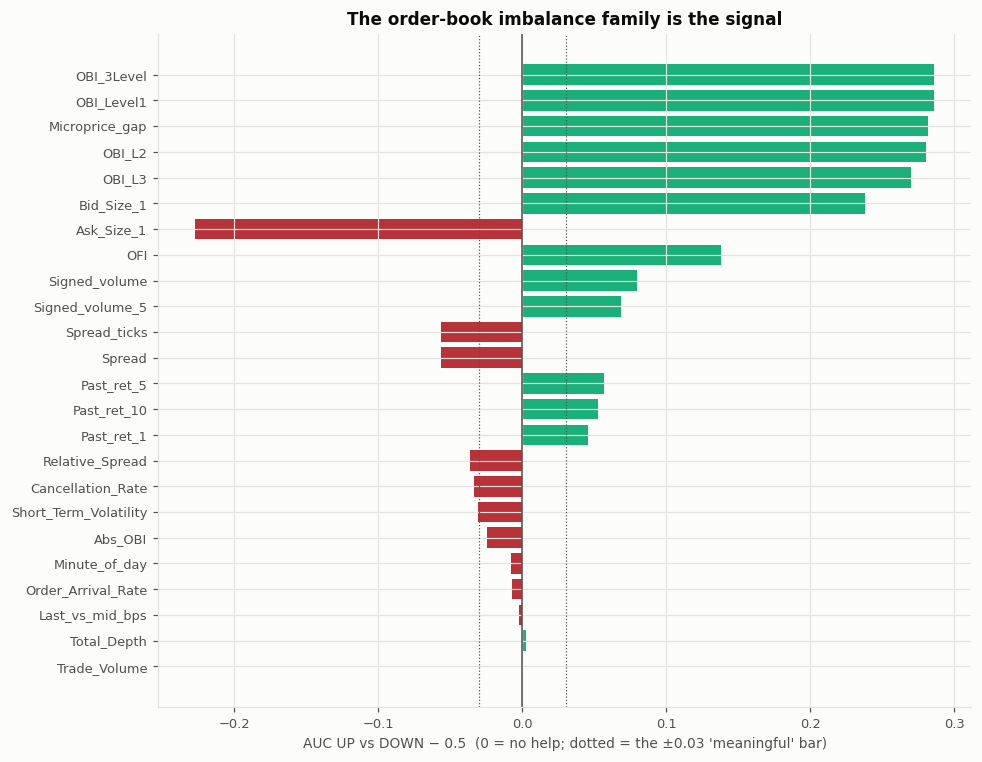

In [3]:
tr = train.copy()
t_tr = pd.to_datetime(tr.Timestamp, dayfirst=True)
moves = tr[TARGET] != "NO_MOVE"
up = (tr[TARGET] == "UP").astype(int)
nomove = (tr[TARGET] == "NO_MOVE").astype(int)
CANDIDATES = ["OBI_Level1", "OBI_3Level", "OBI_L2", "OBI_L3", "Microprice_gap", "OFI", "Past_ret_1", "Past_ret_5", "Past_ret_10",
              "Signed_volume", "Signed_volume_5", "Last_vs_mid_bps", "Trade_Volume", "Order_Arrival_Rate", "Cancellation_Rate",
              "Short_Term_Volatility", "Spread", "Relative_Spread", "Spread_ticks", "Total_Depth", "Minute_of_day", "Abs_OBI",
              "Bid_Size_1", "Ask_Size_1"]
CATEGORIES = ["Trade_Side", "Event_Type", "Stock"]
LINE_INPUTS = 0.05 / (len(CANDIDATES) + len(CATEGORIES))
rows = []
for c in CANDIDATES:
    x = tr[c]; ok = x.notna()
    rows.append({"Input": c, "p": stats.kruskal(*[x[ok & (tr[TARGET] == k)] for k in CLASSES]).pvalue,
                 "AUC UP vs DOWN": roc_auc_score(up[ok & moves], x[ok & moves]),
                 "AUC NO_MOVE vs move": roc_auc_score(nomove[ok], x[ok]),
                 "Rank correlation with next move": stats.spearmanr(x[ok], tr.Future_Return_100ms[ok]).correlation})
for c in CATEGORIES:
    tab = pd.crosstab(tr[c], tr[TARGET]); chi = stats.chi2_contingency(tab)
    rows.append({"Input": c, "p": chi[1], "Cramér's V (0 = no link, 1 = perfect)": np.sqrt(chi[0] / (tab.values.sum() * (min(tab.shape) - 1)))})
evidence = pd.DataFrame(rows)
evidence["Passes the line"] = np.where(evidence.p < LINE_INPUTS, "Yes", "No")
evidence["Meaningful (AUC ≥ 0.03 from 0.5)"] = np.where(
    ((evidence["AUC UP vs DOWN"] - 0.5).abs() >= 0.03) | ((evidence["AUC NO_MOVE vs move"] - 0.5).abs() >= 0.03), "Yes", "No")
evidence = evidence.assign(_s=(evidence["AUC UP vs DOWN"] - 0.5).abs()).sort_values("_s", ascending=False).drop(columns="_s")
print(f"{len(tr):,} training events; {len(evidence)} tests; line 0.05 ÷ {len(evidence)} = {LINE_INPUTS:.4f}")
display(evidence.style.format({"p": "{:.4f}", "AUC UP vs DOWN": "{:.3f}", "AUC NO_MOVE vs move": "{:.3f}",
                               "Rank correlation with next move": "{:+.3f}", "Cramér's V (0 = no link, 1 = perfect)": "{:.3f}"}, na_rep="—").hide(axis="index"))

ev = evidence.dropna(subset=["AUC UP vs DOWN"]).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 7))
strength = ev["AUC UP vs DOWN"] - 0.5
ax.barh(ev.Input, strength, color=[GAIN if v > 0 else LOSS for v in strength])
ax.axvline(0, color=INK_2, lw=1)
for v in (-0.03, 0.03):
    ax.axvline(v, color=INK_2, lw=0.8, ls=":")
ax.set_xlabel("AUC UP vs DOWN − 0.5  (0 = no help; dotted = the ±0.03 'meaningful' bar)")
ax.set_title("The order-book imbalance family is the signal")
fig.tight_layout(); save_chart(fig, "01_input_evidence"); plt.show()

**2b. Inputs against each other.** Inputs that move together carry the same information; keeping all of them only repeats it.

In [4]:
strong = ["OBI_Level1", "OBI_3Level", "OBI_L2", "OBI_L3", "Microprice_gap", "OFI", "Signed_volume", "Signed_volume_5", "Past_ret_1"]
corr = tr[strong].corr(method="spearman")
display(corr.style.format("{:.2f}").background_gradient(cmap="Blues", vmin=0, vmax=1))
print("OBI levels 1–3, OBI over 3 levels and the microprice gap correlate 0.90–0.99: one signal measured several ways.")

,OBI_Level1,OBI_3Level,OBI_L2,OBI_L3,Microprice_gap,OFI,Signed_volume,Signed_volume_5,Past_ret_1
OBI_Level1,1.00,0.99,0.96,0.92,0.98,0.48,0.27,0.23,0.16
OBI_3Level,0.99,1.00,0.98,0.95,0.97,0.47,0.27,0.23,0.16
OBI_L2,0.96,0.98,1.00,0.90,0.95,0.45,0.26,0.23,0.16
OBI_L3,0.92,0.95,0.90,1.00,0.91,0.43,0.25,0.22,0.15
Microprice_gap,0.98,0.97,0.95,0.91,1.00,0.44,0.26,0.24,0.17
OFI,0.48,0.47,0.45,0.43,0.44,1.00,0.12,-0.03,0.01
Signed_volume,0.27,0.27,0.26,0.25,0.26,0.12,1.00,0.44,0.04
Signed_volume_5,0.23,0.23,0.23,0.22,0.24,-0.03,0.44,1.00,0.06
Past_ret_1,0.16,0.16,0.16,0.15,0.17,0.01,0.04,0.06,1.00


OBI levels 1–3, OBI over 3 levels and the microprice gap correlate 0.90–0.99: one signal measured several ways.


**2c. How the next move follows the imbalance**, and whether the last trade's side adds anything once the imbalance is known.

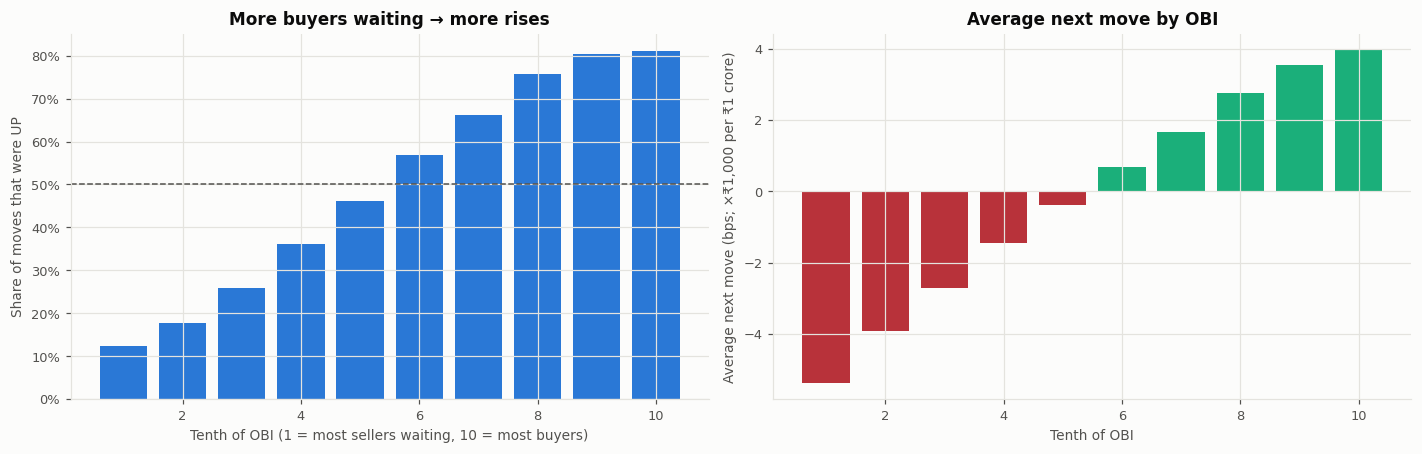

UP share of moves, by OBI third and the last trade's side:


Trade_Side,BUY,SELL
OBI_Level1,,
fewer buyers,21.1%,19.3%
balanced,53.3%,49.7%
more buyers,78.2%,77.6%


In [5]:
dec = pd.qcut(tr.OBI_Level1, 10, labels=False) + 1
up_share = tr[moves].groupby(dec[moves])[TARGET].apply(lambda s: (s == "UP").mean())
mean_bps = tr.groupby(dec).Future_Return_100ms.mean() * 1e4
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].bar(up_share.index, up_share.values, color=BLUE)
axes[0].axhline(0.5, color=INK_2, lw=1, ls="--")
axes[0].set_xlabel("Tenth of OBI (1 = most sellers waiting, 10 = most buyers)"); axes[0].set_ylabel("Share of moves that were UP")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[0].set_title("More buyers waiting → more rises")
axes[1].bar(mean_bps.index, mean_bps.values, color=[GAIN if v > 0 else LOSS for v in mean_bps.values])
axes[1].set_xlabel("Tenth of OBI"); axes[1].set_ylabel("Average next move (bps; ×₹1,000 per ₹1 crore)")
axes[1].set_title("Average next move by OBI")
fig.tight_layout(); save_chart(fig, "02_obi_and_next_move"); plt.show()
third = pd.qcut(tr.OBI_Level1, 3, labels=["fewer buyers", "balanced", "more buyers"])
print("UP share of moves, by OBI third and the last trade's side:")
display(pd.crosstab(third[moves], tr.loc[moves, "Trade_Side"], values=up[moves], aggfunc="mean").style.format("{:.1%}"))

**2d. Questions raised in review (22 Nov 2026):** does trade **size** matter? Does **time of day** matter within each stock? Do the stocks **move together**, and does the rest of the market's imbalance help?

In [6]:
x = tr[moves]
size = x.groupby(["Trade_Side", pd.qcut(x.Trade_Volume, 3, labels=["small", "medium", "large"])])[TARGET].apply(lambda s: (s == "UP").mean()).unstack()
print("UP share by trade side and trade size (moves only):"); display(size.style.format("{:.1%}"))
tr["Hour"] = t_tr.dt.hour
hour_p = {s: stats.chi2_contingency(pd.crosstab(tr[tr.Stock == s].Hour, tr[tr.Stock == s][TARGET]))[1] for s in sorted(tr.Stock.unique())}
print(f"Time of day within each stock (line 0.05 ÷ 10 = 0.005): smallest p {min(hour_p.values()):.3f} ({min(hour_p, key=hour_p.get)}); passing: {sum(p < 0.005 for p in hour_p.values())}")
mid = tr.groupby(["Timestamp", "Stock"]).Mid_Price.last().unstack()
cc = mid.pct_change().corr().values
print(f"Stocks' minute-to-minute price changes move together: average correlation {cc[np.triu_indices(cc.shape[0], 1)].mean():.2f}")

# Rest of the market: each other stock's latest imbalance, from events EARLIER in the file only
market = pd.Series(np.nan, index=df.index)
for day, x_day in df.sort_values("Seq").groupby("Trading_Day"):
    last = {}                                            # each stock's latest imbalance so far today
    for i, s, o in zip(x_day.index, x_day.Stock, x_day.OBI_Level1):
        others = [v for k, v in last.items() if k != s]
        if len(others) >= 5:                             # need at least 5 other stocks seen today
            market.at[i] = np.mean(others)
        last[s] = o                                      # updated AFTER use: only earlier events count
df["Market_OBI"] = market
train, tune, test = split_by_day(df)


def tune_auc(cols):
    a = train[(train[TARGET] != "NO_MOVE") & train[cols].notna().all(axis=1)]
    b = tune[(tune[TARGET] != "NO_MOVE") & tune[cols].notna().all(axis=1)]
    m = LogisticRegression(max_iter=1000).fit(a[cols], a[TARGET] == "UP")
    return roc_auc_score(b[TARGET] == "UP", m.predict_proba(b[cols])[:, 1])


MARKET_AUC = (tune_auc(["OBI_Level1"]), tune_auc(["OBI_Level1", "Market_OBI"]))
print(f"Tuning-day AUC: own OBI {MARKET_AUC[0]:.4f}; own OBI + rest-of-market OBI {MARKET_AUC[1]:.4f} → the market adds nothing")

UP share by trade side and trade size (moves only):


Trade_Volume,small,medium,large
Trade_Side,,,
BUY,57.4%,57.9%,57.5%
SELL,41.8%,41.5%,41.8%


Time of day within each stock (line 0.05 ÷ 10 = 0.005): smallest p 0.009 (NOVA05); passing: 0
Stocks' minute-to-minute price changes move together: average correlation 0.51


Tuning-day AUC: own OBI 0.7795; own OBI + rest-of-market OBI 0.7795 → the market adds nothing


## 3. The inputs the models get (decision M7-08)

**Rule** (as Module 3): keep an input if it passes the line **and** its AUC is at least 0.03 away from 0.5 (for UP vs DOWN or for NO_MOVE). Drop near-duplicates (correlation 0.97 or more) and the raw parts of a kept ratio.
- **Kept (15):** OBI at levels 1, 2, 3; OFI; signed volume (last trade, last 5); past moves over 1, 5, 10 events; spread in ticks; relative spread; short-term volatility; cancellation rate; arrival rate; size of the imbalance.
- **Dropped as duplicates:** microprice gap, OBI over 3 levels, best bid/ask sizes, spread in ₹.
- **Dropped for no signal:** trade volume, total depth, last price vs mid, time of day, event type, stock, rest-of-market OBI.
- **Benchmark: OBI alone** (the simplest rule a trader could use). **Check: all candidate inputs.**

In [7]:
display(pd.DataFrame({"Input": INPUTS, "Meaning": [INPUT_MEANINGS[c] for c in INPUTS]}).style.hide(axis="index"))
ALL_CHECK = CANDIDATES + ["Market_OBI"]
assert not set(INPUTS) & set(LEAKAGE_COLUMNS), "a leakage column is in the inputs"
print(f"{len(INPUTS)} inputs; 'all inputs' check uses {len(ALL_CHECK)}")

Input,Meaning
OBI_Level1,"Order-book imbalance at the best price: (bid size − ask size) ÷ total; +1 all buyers, −1 all sellers"
OBI_L2,Same imbalance at the second-best price level
OBI_L3,Same imbalance at the third-best price level
OFI,Order-flow imbalance: change in best-bid size − change in best-ask size since the stock's last event
Signed_volume,"Last trade's volume, positive for a buy, negative for a sell"
Signed_volume_5,Signed volume added up over the stock's last 5 events
Past_ret_1,Mid-price change since the stock's previous event
Past_ret_5,Mid-price change over the stock's last 5 events
Past_ret_10,Mid-price change over the stock's last 10 events
Spread_ticks,Spread in ticks of ₹0.05


15 inputs; 'all inputs' check uses 25


## 4. Four models compared on the tuning days (decisions M7-09, M7-10)

Every model learns from days 1–14 only and is compared on days 15–17.

| Model | What it does | Settings (fixed in advance) |
| --- | --- | --- |
| **OBI alone** | Logistic regression on the imbalance only: the benchmark | — |
| **Logistic regression** | A weighted sum of the 15 inputs for each class, turned into three percentages that add to 100% | Standardised inputs |
| **Random forest** | 300 decision trees, each on a random sample, averaged | At least 50 events per end leaf |
| **LightGBM** | 400 small trees built one after another, each correcting the last | Learning rate 0.05, at least 100 events per leaf |

**How they're judged:** the **AUC of "chance of UP − chance of DOWN"** for telling real rises from real falls decides (that number drives Task 2's trades); **log-loss** checks the percentages are honest; accuracy (vs 42% for always guessing the commonest class), macro-F1 and each class's hit rate are reported.

In [8]:
def make_model(name: str, weighted: bool = False):
    """A fresh, untrained model with the agreed settings. weighted=True gives NO_MOVE extra weight (check only)."""
    cw = "balanced" if weighted else None
    if name == "OBI alone" or name == "Logistic regression":
        return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=3000, class_weight=cw))
    if name == "Random forest":
        return make_pipeline(SimpleImputer(strategy="median"),
                             RandomForestClassifier(n_estimators=300, min_samples_leaf=50, n_jobs=-1, random_state=SEED, class_weight=cw))
    return lgb.LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=31, min_child_samples=100, subsample=0.8, subsample_freq=1,
                              colsample_bytree=0.8, class_weight=cw, random_state=SEED, verbose=-1)


def inputs_for(name: str) -> list:
    return ["OBI_Level1"] if name == "OBI alone" else INPUTS


def scores(y: pd.Series, P: np.ndarray) -> dict:
    """Every measure for one model's percentages P (columns in CLASSES order: DOWN, NO_MOVE, UP)."""
    pred = np.array(CLASSES)[P.argmax(axis=1)]
    lean = P[:, 2] - P[:, 0]
    mv = (y != "NO_MOVE").values
    return {"AUC UP vs DOWN": roc_auc_score(y[mv] == "UP", lean[mv]), "Log-loss": log_loss(y, P, labels=CLASSES),
            "Accuracy": accuracy_score(y, pred), "Macro-F1": f1_score(y, pred, average="macro"),
            **{f"Hit rate {c}": recall_score(y, pred, labels=[c], average="macro") for c in CLASSES},
            "Share predicted NO_MOVE": float((pred == "NO_MOVE").mean())}


fitted, P_tune, P_test = {}, {}, {}
for name in MODELS:
    fitted[name] = make_model(name).fit(train[inputs_for(name)], train[TARGET])
    P_tune[name] = fitted[name].predict_proba(tune[inputs_for(name)])
    P_test[name] = fitted[name].predict_proba(test[inputs_for(name)])
tune_table = pd.DataFrame([{"Model": n, **scores(tune[TARGET], P_tune[n])} for n in MODELS])
BASE_ACC = tune[TARGET].value_counts(normalize=True).max()
BASE_LL = log_loss(tune[TARGET], np.tile(train[TARGET].value_counts(normalize=True).reindex(CLASSES).values, (len(tune), 1)), labels=CLASSES)
FMT = {"AUC UP vs DOWN": "{:.4f}", "Log-loss": "{:.4f}", "Accuracy": "{:.1%}", "Macro-F1": "{:.3f}", "Hit rate DOWN": "{:.1%}",
       "Hit rate NO_MOVE": "{:.1%}", "Hit rate UP": "{:.1%}", "Share predicted NO_MOVE": "{:.1%}"}
print(f"Tuning days (15–17). Always guessing the commonest class: accuracy {BASE_ACC:.1%}; class shares as percentages: log-loss {BASE_LL:.3f}")
display(tune_table.style.format(FMT).hide(axis="index"))

# The two agreed checks, on the tuning days
chk = []
m_all = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=3000)).fit(train[ALL_CHECK], train[TARGET])
chk.append({"Check": "Logistic regression, all candidate inputs", **scores(tune[TARGET], m_all.predict_proba(tune[ALL_CHECK]))})
for n in COMPARED:
    mw = make_model(n, weighted=True).fit(train[INPUTS], train[TARGET])
    chk.append({"Check": f"{n}, NO_MOVE weighted ('balanced')", **scores(tune[TARGET], mw.predict_proba(tune[INPUTS]))})
checks = pd.DataFrame(chk)
display(checks.style.format(FMT).hide(axis="index"))
BEST_TUNE = tune_table[tune_table.Model != "OBI alone"].sort_values("AUC UP vs DOWN", ascending=False).iloc[0]
print(f"Best on the tuning days: {BEST_TUNE.Model} (AUC {BEST_TUNE['AUC UP vs DOWN']:.4f}, log-loss {BEST_TUNE['Log-loss']:.4f})")

Tuning days (15–17). Always guessing the commonest class: accuracy 42.2%; class shares as percentages: log-loss 1.027


Model,AUC UP vs DOWN,Log-loss,Accuracy,Macro-F1,Hit rate DOWN,Hit rate NO_MOVE,Hit rate UP,Share predicted NO_MOVE
OBI alone,0.7795,0.9189,59.8%,0.435,72.4%,0.0%,70.9%,0.0%
Logistic regression,0.7884,0.9092,60.3%,0.438,71.2%,0.0%,73.1%,0.0%
Random forest,0.7873,0.9104,60.2%,0.438,71.4%,0.0%,72.9%,0.0%
LightGBM,0.7858,0.9137,59.9%,0.435,70.8%,0.0%,72.8%,0.0%


Check,AUC UP vs DOWN,Log-loss,Accuracy,Macro-F1,Hit rate DOWN,Hit rate NO_MOVE,Hit rate UP,Share predicted NO_MOVE
"Logistic regression, all candidate inputs",0.7891,0.9086,60.2%,0.438,71.5%,0.0%,72.8%,0.0%
"Logistic regression, NO_MOVE weighted ('balanced')",0.7883,0.9811,55.4%,0.494,60.4%,25.3%,62.3%,20.3%
"Random forest, NO_MOVE weighted ('balanced')",0.7871,0.9685,57.0%,0.488,63.2%,17.4%,66.4%,13.8%
"LightGBM, NO_MOVE weighted ('balanced')",0.7852,0.9757,55.9%,0.491,61.1%,22.1%,63.9%,17.6%


Best on the tuning days: Logistic regression (AUC 0.7884, log-loss 0.9092)


## 5. The test days: the result, and does any model beat OBI alone?

The test days (18–20, 17,876 events) are used **once**. Each model's AUC is compared with OBI alone's on the same events with **DeLong's test** (the standard test for two AUCs on the same cases). A model beats the benchmark only if it is higher with **p < 0.05 ÷ 3 = 0.017**. If none does, the simplest rule, **OBI alone**, goes to Task 2 (decision M7-10).

In [9]:
def delong_test(y_true: np.ndarray, s1: np.ndarray, s2: np.ndarray) -> tuple:
    """DeLong's test for two correlated AUCs (same events). Returns (AUC1, AUC2, p two-sided).
    Each AUC is built from 'placement values' (how each case ranks against the other class); their
    covariance gives the uncertainty of the difference."""
    pos, neg = y_true == 1, y_true == 0
    m, n = pos.sum(), neg.sum()
    aucs, v01, v10 = [], [], []
    for s in (s1, s2):
        all_r = stats.rankdata(np.concatenate([s[pos], s[neg]]))
        pos_r, neg_r = stats.rankdata(s[pos]), stats.rankdata(s[neg])
        aucs.append((all_r[:m].sum() - m * (m + 1) / 2) / (m * n))
        v01.append((all_r[:m] - pos_r) / n)
        v10.append(1 - (all_r[m:] - neg_r) / m)
    S = np.cov(np.vstack(v01)) / m + np.cov(np.vstack(v10)) / n
    se = np.sqrt(S[0, 0] + S[1, 1] - 2 * S[0, 1])            # uncertainty of the AUC difference
    z = (aucs[0] - aucs[1]) / se
    return aucs[0], aucs[1], 2 * stats.norm.sf(abs(z)), se


test_table = pd.DataFrame([{"Model": n, **scores(test[TARGET], P_test[n])} for n in MODELS])
mv = (test[TARGET] != "NO_MOVE").values
y_mv = (test[TARGET][mv] == "UP").astype(int).values
lean_obi = (P_test["OBI alone"][:, 2] - P_test["OBI alone"][:, 0])[mv]
rows = []
for n in COMPARED:
    a1, a0, p, se = delong_test(y_mv, (P_test[n][:, 2] - P_test[n][:, 0])[mv], lean_obi)
    rows.append({"Model": n, "AUC gain over OBI alone": a1 - a0, "Gain 95% range": f"{a1 - a0 - 1.96 * se:+.4f} to {a1 - a0 + 1.96 * se:+.4f}", "p (DeLong)": p,
                 "Beats OBI alone?": "Yes" if (p < LINE_MODELS and a1 > a0) else "No"})
vs_obi = pd.DataFrame(rows)
test_table = test_table.merge(vs_obi, on="Model", how="left")
TEST_BASE = test[TARGET].value_counts(normalize=True).max()
print(f"Test days (18–20), {len(test):,} events. Always guessing the commonest class: {TEST_BASE:.1%}. Line for beating OBI alone: {LINE_MODELS:.3f}")
display(test_table.style.format({**FMT, "AUC gain over OBI alone": "{:+.4f}", "p (DeLong)": "{:.4f}"}, na_rep="—").hide(axis="index"))

winners = test_table[test_table["Beats OBI alone?"] == "Yes"]
CHOSEN = (winners.sort_values("AUC UP vs DOWN", ascending=False).Model.iloc[0] if len(winners) else "OBI alone")
if len(winners) and test_table.set_index("Model").loc[CHOSEN, "Log-loss"] > test_table.set_index("Model").loc["OBI alone", "Log-loss"]:
    CHOSEN = "OBI alone"                     # second check: less honest percentages than the benchmark → not chosen
print(f"Model passed to Task 2: {CHOSEN}")
cm = pd.DataFrame(confusion_matrix(test[TARGET], np.array(CLASSES)[P_test[CHOSEN].argmax(1)], labels=CLASSES),
                  index=[f"Actual {c}" for c in CLASSES], columns=[f"Predicted {c}" for c in CLASSES])
print(f"Confusion matrix, {CHOSEN}, test days (rows = what happened, columns = what was predicted):")
display(cm)

Test days (18–20), 17,876 events. Always guessing the commonest class: 42.0%. Line for beating OBI alone: 0.017


Model,AUC UP vs DOWN,Log-loss,Accuracy,Macro-F1,Hit rate DOWN,Hit rate NO_MOVE,Hit rate UP,Share predicted NO_MOVE,AUC gain over OBI alone,Gain 95% range,p (DeLong),Beats OBI alone?
OBI alone,0.7811,0.9175,60.1%,0.437,71.6%,0.0%,72.4%,0.0%,—,—,—,—
Logistic regression,0.7914,0.9076,60.6%,0.440,70.1%,0.0%,75.1%,0.0%,+0.0102,+0.0083 to +0.0122,0.0000,Yes
Random forest,0.7888,0.9100,60.6%,0.440,70.4%,0.0%,74.8%,0.0%,+0.0076,+0.0058 to +0.0095,0.0000,Yes
LightGBM,0.7889,0.9116,60.5%,0.439,70.3%,0.0%,74.6%,0.0%,+0.0078,+0.0054 to +0.0102,0.0000,Yes


Model passed to Task 2: Logistic regression
Confusion matrix, Logistic regression, test days (rows = what happened, columns = what was predicted):


,Predicted DOWN,Predicted NO_MOVE,Predicted UP
Actual DOWN,5194,0,2218
Actual NO_MOVE,1354,0,1609
Actual UP,1864,0,5637


## 5b. Overfitting check: training days vs unseen days

**Overfitting** = a model learning quirks of its training data that don't repeat. It shows as a much higher score on the training days than on unseen days. A gap of a few thousandths of AUC is normal; a large gap means the model learned noise.

In [10]:
over = []
for n in MODELS:
    P_tr = fitted[n].predict_proba(train[inputs_for(n)])
    a_tr = scores(train[TARGET], P_tr)["AUC UP vs DOWN"]
    a_tu = tune_table.set_index("Model").loc[n, "AUC UP vs DOWN"]
    a_te = test_table.set_index("Model").loc[n, "AUC UP vs DOWN"]
    over.append({"Model": n, "Training days (seen)": a_tr, "Tuning days (unseen)": a_tu, "Test days (unseen)": a_te, "Gap: training − test": a_tr - a_te})
overfit = pd.DataFrame(over)
display(overfit.style.format({c: "{:.4f}" for c in overfit.columns if c != "Model"} | {"Gap: training − test": "{:+.4f}"}).hide(axis="index"))
print("The trees score higher on the days they learned from; logistic regression's gap is the smallest, so it generalises best.")

Model,Training days (seen),Tuning days (unseen),Test days (unseen),Gap: training − test
OBI alone,0.7860,0.7795,0.7811,+0.0049
Logistic regression,0.7940,0.7884,0.7914,+0.0026
Random forest,0.8318,0.7873,0.7888,+0.0430
LightGBM,0.8418,0.7858,0.7889,+0.0529


The trees score higher on the days they learned from; logistic regression's gap is the smallest, so it generalises best.


## 5c. Does it hold everywhere? By stock and by day

A model that works only for some stocks or on some days would be fragile. Test days, the chosen model vs OBI alone.

In [11]:
def auc_of(part_mask, name):
    y = test[TARGET][part_mask]; mvp = (y != "NO_MOVE").values
    lean = (P_test[name][:, 2] - P_test[name][:, 0])[part_mask.values][mvp]
    return roc_auc_score(y[mvp] == "UP", lean)


by_stock = pd.DataFrame([{"Stock": s_, CHOSEN: auc_of(test.Stock == s_, CHOSEN), "OBI alone": auc_of(test.Stock == s_, "OBI alone")}
                         for s_ in sorted(test.Stock.unique())])
by_stock["Gain"] = by_stock[CHOSEN] - by_stock["OBI alone"]
by_day = pd.DataFrame([{"Day": f"{d_:%d %b}", CHOSEN: auc_of(test.Trading_Day == d_, CHOSEN), "OBI alone": auc_of(test.Trading_Day == d_, "OBI alone")}
                       for d_ in sorted(test.Trading_Day.unique())])
by_day["Gain"] = by_day[CHOSEN] - by_day["OBI alone"]
display(by_stock.style.format({CHOSEN: "{:.3f}", "OBI alone": "{:.3f}", "Gain": "{:+.3f}"}).hide(axis="index"))
display(by_day.style.format({CHOSEN: "{:.3f}", "OBI alone": "{:.3f}", "Gain": "{:+.3f}"}).hide(axis="index"))
print(f"{CHOSEN} beats OBI alone in {(by_stock.Gain > 0).sum()} of {len(by_stock)} stocks and {(by_day.Gain > 0).sum()} of {len(by_day)} days; "
      f"AUC by stock {by_stock[CHOSEN].min():.3f}–{by_stock[CHOSEN].max():.3f}")

Stock,Logistic regression,OBI alone,Gain
NOVA01,0.792,0.786,+0.005
NOVA02,0.785,0.772,+0.014
NOVA03,0.803,0.796,+0.007
NOVA04,0.804,0.793,+0.011
NOVA05,0.774,0.762,+0.012
NOVA06,0.806,0.796,+0.010
NOVA07,0.803,0.793,+0.011
NOVA08,0.790,0.780,+0.010
NOVA09,0.778,0.764,+0.013
NOVA10,0.779,0.770,+0.008


Day,Logistic regression,OBI alone,Gain
28 Jan,0.789,0.779,+0.010
29 Jan,0.792,0.784,+0.009
30 Jan,0.793,0.782,+0.012


Logistic regression beats OBI alone in 10 of 10 stocks and 3 of 3 days; AUC by stock 0.774–0.806


## 5d. Better than luck? The shuffled-label test

The same standard as Modules 1, 4 and 5: shuffle what actually happened (UP / DOWN / NO_MOVE) **within each training day**, so the link between the order book and the next move is broken but each day's mix of outcomes is kept. Refit the chosen model 100 times and score it on the tuning days. If the real model's AUC is far above every shuffled run, its skill is not luck.

```text
p = (shuffled runs scoring at least as high as the real model + 1) ÷ (100 + 1)      smallest possible p = 0.0099
```

In [12]:
rng = np.random.default_rng(SEED)
real_auc = tune_table.set_index("Model").loc[CHOSEN, "AUC UP vs DOWN"]
y_shuffled = train[TARGET].copy()
null = []
mv_tune = (tune[TARGET] != "NO_MOVE").values
for _ in range(100):
    for d_ in train.Trading_Day.unique():                      # shuffle within each day
        idx = np.where(train.Trading_Day.values == d_)[0]
        y_shuffled.iloc[idx] = rng.permutation(train[TARGET].values[idx])
    m = make_model(CHOSEN).fit(train[inputs_for(CHOSEN)], y_shuffled)
    Pn = m.predict_proba(tune[inputs_for(CHOSEN)])
    null.append(roc_auc_score(tune[TARGET][mv_tune] == "UP", (Pn[:, 2] - Pn[:, 0])[mv_tune]))
P_SHUFFLE = (1 + np.sum(np.array(null) >= real_auc)) / 101
print(f"Shuffled labels: AUC {np.mean(null):.3f} on average (95% range {np.percentile(null, 2.5):.3f}–{np.percentile(null, 97.5):.3f}); "
      f"real model {real_auc:.3f}; p = {P_SHUFFLE:.4f}")

Shuffled labels: AUC 0.542 on average (95% range 0.417–0.672); real model 0.788; p = 0.0099


## 5e. Choosing the model: the factors in plain words

The agreed rule (decision M7-10) picks the model; this table shows the same choice factor by factor, as for every other module.

In [13]:
tt = test_table.set_index("Model"); of = overfit.set_index("Model")
EXPLAIN = {"OBI alone": "Yes: one number", "Logistic regression": "Yes: one weight per input (step 6b)",
           "Random forest": "Partly: 300 trees, only importance scores", "LightGBM": "Partly: 400 trees, only importance scores"}
SPEED = {"OBI alone": "Instant", "Logistic regression": "About 1 second", "Random forest": "About a minute", "LightGBM": "About 15 seconds"}
factors = pd.DataFrame([{"Model": n,
    "Tells rises from falls (test AUC; higher = better)": f"{tt.loc[n, 'AUC UP vs DOWN']:.3f}",
    "Honest percentages (log-loss; lower = better)": f"{tt.loc[n, 'Log-loss']:.3f}",
    "Beats the simple balance rule beyond chance?": "—" if n == "OBI alone" else f"{tt.loc[n, 'Beats OBI alone?']} (+{tt.loc[n, 'AUC gain over OBI alone']:.3f}; range {tt.loc[n, 'Gain 95% range']})",
    "Learned noise? (training − test AUC)": f"{of.loc[n, 'Gap: training − test']:+.3f}",
    "Can you see why it predicts?": EXPLAIN[n], "Training time": SPEED[n],
    "Chosen?": "Yes" if n == CHOSEN else ""} for n in MODELS])
display(factors.style.hide(axis="index"))

Model,Tells rises from falls (test AUC; higher = better),Honest percentages (log-loss; lower = better),Beats the simple balance rule beyond chance?,Learned noise? (training − test AUC),Can you see why it predicts?,Training time,Chosen?
OBI alone,0.781,0.917,—,+0.005,Yes: one number,Instant,
Logistic regression,0.791,0.908,Yes (+0.010; range +0.0083 to +0.0122),+0.003,Yes: one weight per input (step 6b),About 1 second,Yes
Random forest,0.789,0.910,Yes (+0.008; range +0.0058 to +0.0095),+0.043,"Partly: 300 trees, only importance scores",About a minute,
LightGBM,0.789,0.912,Yes (+0.008; range +0.0054 to +0.0102),+0.053,"Partly: 400 trees, only importance scores",About 15 seconds,


## 6. Are the percentages honest? And NO_MOVE (decision M7-11)

**Honest percentages (calibration):** group test events by the model's chance of UP; in each group, the share that actually rose should match. Task 2 compares these percentages with trading costs, so they must be honest.

**NO_MOVE:** it stays in the data and every measure; the model gives a chance of NO_MOVE for every event. It is never the *predicted* class because that chance never comes out highest: the data can't say *when* a no-move will happen.

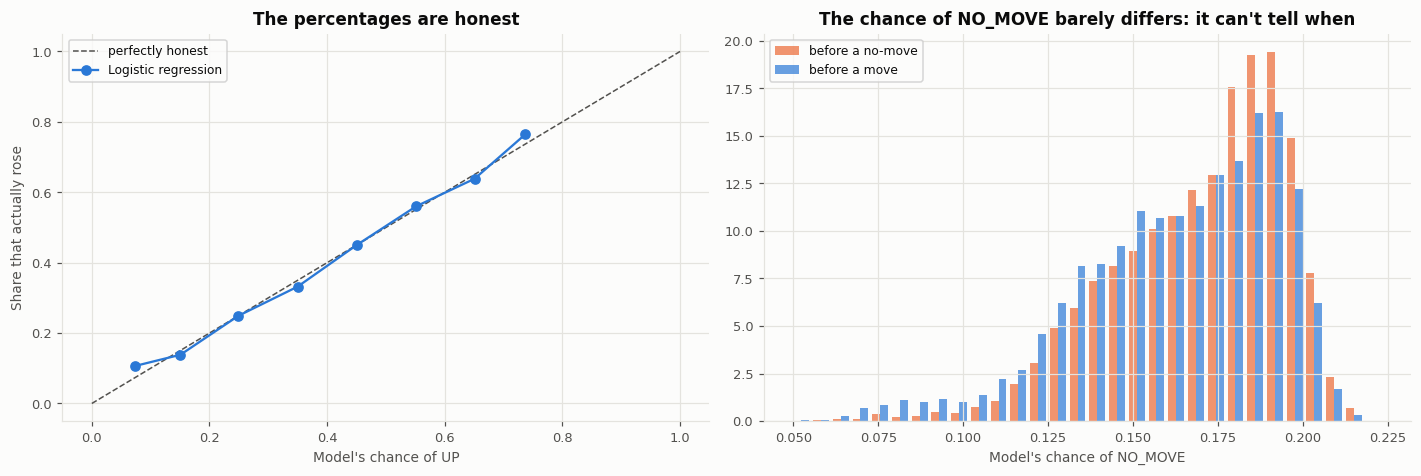

Chance of NO_MOVE on the test days: 5% to 22% (typical 17%); typical before real no-moves 17.6% vs before moves 16.8%


In [14]:
P = P_test[CHOSEN]
bins = pd.cut(P[:, 2], np.arange(0, 1.01, 0.1))
calib = pd.DataFrame({"bin": bins, "pred": P[:, 2], "act": (test[TARGET] == "UP").values}).groupby("bin", observed=True).agg(
    events=("act", "size"), predicted=("pred", "mean"), actual=("act", "mean")).query("events >= 50")
pn = P[:, 1]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
axes[0].plot([0, 1], [0, 1], color=INK_2, ls="--", lw=1, label="perfectly honest")
axes[0].plot(calib.predicted, calib.actual, marker="o", color=BLUE, label=CHOSEN)
axes[0].set_xlabel("Model's chance of UP"); axes[0].set_ylabel("Share that actually rose")
axes[0].set_title("The percentages are honest"); axes[0].legend(fontsize=8)
axes[1].hist([pn[test[TARGET].values == "NO_MOVE"], pn[test[TARGET].values != "NO_MOVE"]], bins=30, density=True,
             color=[ORANGE, BLUE], alpha=0.7, label=["before a no-move", "before a move"])
axes[1].set_xlabel("Model's chance of NO_MOVE"); axes[1].set_title("The chance of NO_MOVE barely differs: it can't tell when")
axes[1].legend(fontsize=8)
fig.tight_layout(); save_chart(fig, "03_honest_percentages_and_no_move"); plt.show()
print(f"Chance of NO_MOVE on the test days: {pn.min():.0%} to {pn.max():.0%} (typical {np.median(pn):.0%}); "
      f"typical before real no-moves {np.median(pn[test[TARGET].values == 'NO_MOVE']):.1%} vs before moves {np.median(pn[test[TARGET].values != 'NO_MOVE']):.1%}")

## 6b. What the model relies on

Logistic regression gives one weight per input for each outcome. The table shows, for each input, how a **one-typical-step rise in it** (one standard deviation) changes the odds of **a rise rather than a fall**:

```text
Odds multiplier = e^(weight for UP − weight for DOWN)        above 1 → favours a rise; below 1 → favours a fall
Example: × 2.0 means one typical step up in the input doubles the odds of a rise over a fall
```

Inputs move together (the three OBI levels especially), so read the weights as "what the model leans on", not as separate causes.

In [15]:
lr = fitted["Logistic regression"][-1]                         # the fitted logistic regression inside the pipeline
cls = list(lr.classes_)
w = lr.coef_[cls.index("UP")] - lr.coef_[cls.index("DOWN")]
drivers = pd.DataFrame({"Input": INPUTS, "Meaning": [INPUT_MEANINGS[c] for c in INPUTS], "Weight (UP vs DOWN)": w,
                        "Odds multiplier per typical step": np.exp(w)}).assign(_a=lambda d: d["Weight (UP vs DOWN)"].abs())
drivers = drivers.sort_values("_a", ascending=False).drop(columns="_a")
PLAIN = {"OBI_Level1": "more buyers than sellers waiting at the best price", "OBI_L2": "more buyers than sellers at the second-best price",
         "OBI_L3": "more buyers than sellers at the third-best price", "OFI": "buying interest growing since the last moment",
         "Signed_volume": "the last trade being a bigger purchase", "Signed_volume_5": "more buying in the last 5 trades",
         "Past_ret_1": "the price having just risen", "Past_ret_5": "the price having risen over the last 5 moments",
         "Past_ret_10": "the price having risen over the last 10 moments", "Spread_ticks": "a wider gap between buying and selling prices",
         "Relative_Spread": "a wider gap as a share of the price", "Short_Term_Volatility": "a more jumpy price",
         "Cancellation_Rate": "orders being cancelled faster", "Order_Arrival_Rate": "new orders arriving faster",
         "Abs_OBI": "a bigger imbalance either way"}
drivers["In plain words"] = [f"With {PLAIN[c]}, a {'rise' if v > 0 else 'fall'} is more likely: odds × {np.exp(v):.2f} per typical step"
                             if abs(v) >= 0.05 else f"{PLAIN[c].capitalize()}: almost no effect once the others are known (odds × {np.exp(v):.2f})"
                             for c, v in zip(drivers.Input, drivers["Weight (UP vs DOWN)"])]
display(drivers.style.format({"Weight (UP vs DOWN)": "{:+.3f}", "Odds multiplier per typical step": "{:.2f}"}).hide(axis="index"))

Input,Meaning,Weight (UP vs DOWN),Odds multiplier per typical step,In plain words
OBI_Level1,"Order-book imbalance at the best price: (bid size − ask size) ÷ total; +1 all buyers, −1 all sellers",+0.873,2.39,"With more buyers than sellers waiting at the best price, a rise is more likely: odds × 2.39 per typical step"
Spread_ticks,Spread in ticks of ₹0.05,-0.298,0.74,"With a wider gap between buying and selling prices, a fall is more likely: odds × 0.74 per typical step"
OBI_L2,Same imbalance at the second-best price level,+0.248,1.28,"With more buyers than sellers at the second-best price, a rise is more likely: odds × 1.28 per typical step"
Order_Arrival_Rate,How fast new orders arrive (given),+0.113,1.12,"With new orders arriving faster, a rise is more likely: odds × 1.12 per typical step"
Cancellation_Rate,How fast orders are being cancelled (given),-0.093,0.91,"With orders being cancelled faster, a fall is more likely: odds × 0.91 per typical step"
OBI_L3,Same imbalance at the third-best price level,+0.091,1.09,"With more buyers than sellers at the third-best price, a rise is more likely: odds × 1.09 per typical step"
Past_ret_5,Mid-price change over the stock's last 5 events,-0.023,0.98,The price having risen over the last 5 moments: almost no effect once the others are known (odds × 0.98)
Past_ret_10,Mid-price change over the stock's last 10 events,+0.012,1.01,The price having risen over the last 10 moments: almost no effect once the others are known (odds × 1.01)
Signed_volume,"Last trade's volume, positive for a buy, negative for a sell",+0.009,1.01,The last trade being a bigger purchase: almost no effect once the others are known (odds × 1.01)
Past_ret_1,Mid-price change since the stock's previous event,-0.002,1.00,The price having just risen: almost no effect once the others are known (odds × 1.00)


## 7. What Task 1 means for Task 2 (review of the agreed Task 2 rules)

Task 2's rules were agreed before Task 1 was built. This step checks, **on the tuning days** (so the test days stay untouched for Task 2), whether what Task 1 found should change them (project working rule: review each task's results before building the next).

Four questions, using the chosen model's **lean** (chance of a rise − chance of a fall), which Task 2 trades on:
1. **Does the move caught grow with the lean?** "Move caught" = the next move if you had bought when the lean is positive (or sold when negative). If it grows steadily, the lean can estimate each trade's **expected gain**.
2. **Does the spread change with the model's confidence?** The spread is a trade's main cost after charges.
3. **Do confident moments end in no move less often?** A no-move trade earns nothing but pays every cost.
4. **Are the percentages honest?** (Step 6: yes.) Only honest percentages can be turned into an expected gain.

Move caught ≈ 7.09 bps × |lean| (fitted on the tuning days): a lean of 0.5 → about 3.5 bps = ₹3,546 per ₹1 crore before costs


,Typical |lean|,Move caught (bps),Spread (bps),No-move share,Move caught (₹ per ₹1 crore),Spread (₹ per ₹1 crore)
Tenth of |lean|,,,,,,
1,0.04,+0.27,1.10,20.9%,₹+267,"₹1,103"
2,0.12,+0.66,1.11,20.1%,₹+658,"₹1,113"
3,0.20,+1.08,1.14,19.0%,"₹+1,079","₹1,137"
4,0.28,+1.71,1.23,18.2%,"₹+1,715","₹1,232"
5,0.35,+2.24,1.30,17.3%,"₹+2,244","₹1,300"
6,0.41,+2.79,1.38,16.5%,"₹+2,793","₹1,375"
7,0.47,+3.31,1.40,15.3%,"₹+3,305","₹1,402"
8,0.53,+3.85,1.39,12.9%,"₹+3,848","₹1,388"
9,0.60,+4.28,1.40,14.3%,"₹+4,281","₹1,398"


Most confident tenth vs least: spread 1.77 vs 1.10 bps; no-move share 10.5% vs 20.9%


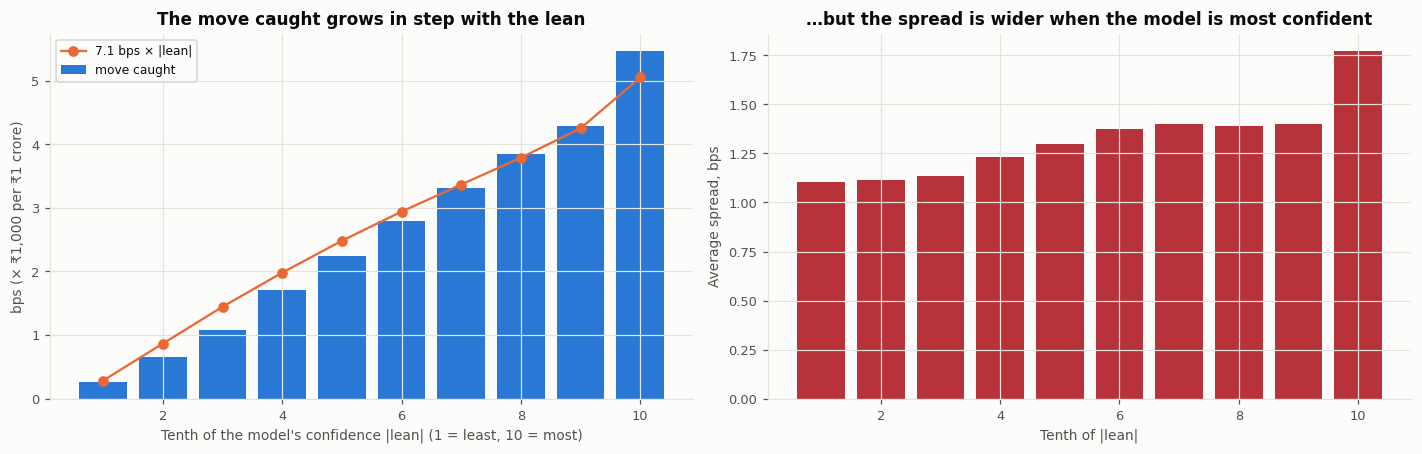

What Task 1 found,What it means for Task 2
The move caught grows in step with the lean (about 7.1 bps × |lean|),Each trade's expected gain can be estimated from the lean
The percentages are honest (step 6),That estimate can be trusted enough to weigh against costs
Spreads are wider when the model is most confident (1.77 vs 1.10 bps),A single confidence cut-off trades exactly where costs are highest: compare each moment's expected gain with that moment's own cost instead (revision of decision M7-13)
Confident moments end in no move less often (10.5% vs 20.9%),The 'don't trade' zone for weak leans also avoids most no-move trades (decision M7-11 holds)
Almost all skill is in the buyer/seller balance; logistic regression beats it slightly,Use logistic regression; show OBI alone as a comparison (decision M7-10 holds)


In [16]:
lean_t = P_tune[CHOSEN][:, 2] - P_tune[CHOSEN][:, 0]
mv_t = tune.Future_Return_100ms.values * 1e4                       # the next move in bps (scoring only)
caught = np.sign(lean_t) * mv_t                                     # the move a trade in the lean's direction catches
spread_t = tune.Relative_Spread.values * 1e4
review = pd.DataFrame({"lean": np.abs(lean_t), "caught": caught, "spread": spread_t, "nomove": (tune[TARGET] == "NO_MOVE").values})
review["Tenth of |lean|"] = pd.qcut(review.lean, 10, labels=False) + 1
by_tenth = review.groupby("Tenth of |lean|").agg(**{"Typical |lean|": ("lean", "mean"), "Move caught (bps)": ("caught", "mean"),
                                                     "Spread (bps)": ("spread", "mean"), "No-move share": ("nomove", "mean")})
by_tenth["Move caught (₹ per ₹1 crore)"] = by_tenth["Move caught (bps)"] * BPS_TO_RUPEES
by_tenth["Spread (₹ per ₹1 crore)"] = by_tenth["Spread (bps)"] * BPS_TO_RUPEES
SLOPE = float((review.lean * review.caught).sum() / (review.lean ** 2).sum())     # move caught ≈ SLOPE × |lean| (through zero)
print(f"Move caught ≈ {SLOPE:.2f} bps × |lean| (fitted on the tuning days): a lean of 0.5 → about {SLOPE * 0.5:.1f} bps "
      f"= ₹{SLOPE * 0.5 * BPS_TO_RUPEES:,.0f} per ₹1 crore before costs")
display(by_tenth.style.format({"Typical |lean|": "{:.2f}", "Move caught (bps)": "{:+.2f}", "Spread (bps)": "{:.2f}", "No-move share": "{:.1%}",
                              "Move caught (₹ per ₹1 crore)": "₹{:+,.0f}", "Spread (₹ per ₹1 crore)": "₹{:,.0f}"}))
top, bottom = by_tenth.iloc[-1], by_tenth.iloc[0]
print(f"Most confident tenth vs least: spread {top['Spread (bps)']:.2f} vs {bottom['Spread (bps)']:.2f} bps; "
      f"no-move share {top['No-move share']:.1%} vs {bottom['No-move share']:.1%}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].bar(by_tenth.index, by_tenth["Move caught (bps)"], color=BLUE, label="move caught")
axes[0].plot(by_tenth.index, SLOPE * by_tenth["Typical |lean|"], color=ORANGE, marker="o", label=f"{SLOPE:.1f} bps × |lean|")
axes[0].set_xlabel("Tenth of the model's confidence |lean| (1 = least, 10 = most)"); axes[0].set_ylabel("bps (× ₹1,000 per ₹1 crore)")
axes[0].set_title("The move caught grows in step with the lean"); axes[0].legend(fontsize=8)
axes[1].bar(by_tenth.index, by_tenth["Spread (bps)"], color=LOSS)
axes[1].set_xlabel("Tenth of |lean|"); axes[1].set_ylabel("Average spread, bps")
axes[1].set_title("…but the spread is wider when the model is most confident")
fig.tight_layout(); save_chart(fig, "04_what_task1_means_for_task2"); plt.show()

IMPLICATIONS = pd.DataFrame([
    {"What Task 1 found": f"The move caught grows in step with the lean (about {SLOPE:.1f} bps × |lean|)",
     "What it means for Task 2": "Each trade's expected gain can be estimated from the lean"},
    {"What Task 1 found": "The percentages are honest (step 6)",
     "What it means for Task 2": "That estimate can be trusted enough to weigh against costs"},
    {"What Task 1 found": f"Spreads are wider when the model is most confident ({top['Spread (bps)']:.2f} vs {bottom['Spread (bps)']:.2f} bps)",
     "What it means for Task 2": "A single confidence cut-off trades exactly where costs are highest: compare each moment's expected gain with that moment's own cost instead (revision of decision M7-13)"},
    {"What Task 1 found": f"Confident moments end in no move less often ({top['No-move share']:.1%} vs {bottom['No-move share']:.1%})",
     "What it means for Task 2": "The 'don't trade' zone for weak leans also avoids most no-move trades (decision M7-11 holds)"},
    {"What Task 1 found": "Almost all skill is in the buyer/seller balance; logistic regression beats it slightly",
     "What it means for Task 2": "Use logistic regression; show OBI alone as a comparison (decision M7-10 holds)"},
])
display(IMPLICATIONS.style.hide(axis="index"))

## 8. What the results say

**In one sentence: yes, the order book predicts the next tenth of a second's price move well, mostly from one number, the balance of waiting buyers and sellers. Machine learning adds a small but real improvement.**

### What the data showed (step 2, training days only)
- **The signal is the imbalance between waiting buyers and sellers (OBI).**
  - When far more shares wait to be sold than bought (the lowest tenth of OBI), only 12% of moves are rises. The average next move is −5.4 bps (−₹5,400 per ₹1 crore).
  - When far more wait to be bought (the highest tenth), 81% are rises, averaging +4.0 bps (+₹4,000 per ₹1 crore).
- **Other inputs add a little:** the change in waiting orders since the last moment (OFI), the last trades' direction, and recent price moves.
- **Things that don't matter here:** the size of a trade (big and small buys lead to the same rises), time of day, which stock, event type, and the rest of the market's imbalance (the stocks move together, but each stock's own book already shows it).
- **NO_MOVE can't be foreseen:** no input tells a coming no-move apart from a coming move.

### The models (steps 4–5)

| Model | AUC, rises vs falls (0.5 = coin flip) | Log-loss (lower = more honest %) | Right class | Beats OBI alone? |
| --- | --- | --- | --- | --- |
| OBI alone (benchmark) | 0.781 | 0.917 | 60.1% | — |
| **Logistic regression** | **0.791** | **0.908** | **60.6%** | **Yes (p < 0.0001)** |
| Random forest | 0.789 | 0.910 | 60.6% | Yes (p < 0.0001) |
| LightGBM | 0.789 | 0.912 | 60.5% | Yes (p < 0.0001) |

*Test days 18–20, 17,876 moments, used once. Always guessing the commonest class is right 42.0% of the time.*

- **Every model is far better than guessing:** about 60% right vs 42%.
- **All three models beat OBI alone beyond chance, but by a small margin:** +0.008 to +0.010 AUC. With about 15,000 rises and falls to test on, even a small gain is clearly real (the line was 0.017).
- **Logistic regression is best and goes to Task 2.** The tree models don't beat it, because the link between the imbalance and the next move is close to a straight line.
- **The percentages are honest** (step 6): of moments given about a 70% chance of a rise, about 70% rose.

### Is the result solid? (steps 5b–5e)

| Check | Result | What it means |
| --- | --- | --- |
| **Overfitting** (training-day AUC − test-day AUC) | Logistic regression +0.003; OBI alone +0.005; random forest +0.043; LightGBM +0.053 | The trees learned some noise from the training days; logistic regression didn't |
| **Holds everywhere?** | Logistic regression beats OBI alone in **all 10 stocks** (AUC 0.774–0.806) and **all 3 test days** | Not a quirk of one stock or one day |
| **Better than luck?** (shuffled outcomes, 100 refits) | Shuffled models score an AUC of 0.54 on average (95% range 0.42–0.67); the real model scores 0.79; p = 0.0099, the smallest possible with 100 runs | The skill is real |
| **How big is the gain over the simple rule?** | +0.010 AUC; 95% range +0.008 to +0.012 | Small but clearly above zero |

**Choosing the model, factor by factor (step 5e):**

| Factor | OBI alone | **Logistic regression** | Random forest | LightGBM |
| --- | --- | --- | --- | --- |
| Tells rises from falls (test AUC) | 0.781 | **0.791** | 0.789 | 0.789 |
| Honest percentages (log-loss, lower = better) | 0.917 | **0.908** | 0.910 | 0.912 |
| Learned noise? (training − test AUC) | +0.005 | **+0.003** | +0.043 | +0.053 |
| Can you see why it predicts? | Yes | **Yes: one weight per input** | Partly | Partly |
| Training time | Instant | About 1 second | About a minute | About 15 seconds |

Logistic regression is best or joint-best on every factor, so it goes to Task 2.

### What the model relies on (step 6b)
The odds of a rise rather than a fall, for one typical step up in each input, with the others held fixed:
- **More buyers than sellers waiting at the best price:** odds × **2.39**. This is by far the main driver.
- **A wider gap between buying and selling prices:** odds × **0.74**, so a fall is more likely. Wide spreads lean towards falls in this data.
- **More buyers than sellers at the second-best price:** × 1.28. At the third-best: × 1.09.
- **New orders arriving faster:** × 1.12. **Orders being cancelled faster:** × 0.91.
- **Everything else adds almost nothing once those are known.** That includes recent trades, recent price moves and the change in waiting orders: they each moved the odds alone in step 2, but they carry the same information as the imbalance.

### NO_MOVE
- It stays in every measure (16.5% of moments) and gets its own chance on every row: 5% to 22%, typically 17%.
- It is never the predicted class. Its chance is barely higher before real no-moves (17.6%) than before moves (16.8%), so the model knows no-moves happen about 1 time in 6, but not when.
- Giving NO_MOVE extra weight catches 17–25% of them, but costs 3–5 points of accuracy and makes the percentages less honest. So the models stay unweighted (decision M7-11).

### What Task 1 means for Task 2 (step 7, tuning days)

Task 2's rules were agreed before Task 1 existed. Reviewing them against what Task 1 actually found:

| What Task 1 found | What it means for Task 2 |
| --- | --- |
| **The move caught grows in step with the lean:** from +0.27 bps in the least confident tenth of moments to +5.46 bps in the most; about **7.1 bps × the lean** | Each trade's **expected gain** can be estimated from the lean |
| **The percentages are honest** (step 6) | That estimate can be trusted enough to weigh against costs |
| **Spreads are widest when the model is most confident:** 1.77 bps in the most confident tenth vs 1.10 in the least | A single confidence cut-off trades exactly where costs are highest. **Revise Task 2's rule (decision M7-13):** trade only when the expected gain beats **that moment's own cost** |
| **Confident moments end in no move less often:** 10.5% vs 20.9% | The "don't trade" zone also avoids most no-move trades (decision M7-11 holds) |
| **Almost all skill is in the buyer/seller balance;** logistic regression beats it slightly | Use logistic regression in Task 2; show OBI alone as a comparison (decision M7-10 holds) |

### What goes to Task 2
- `FINAL_M7_T1_direction_predictions.csv`: for every tuning- and test-day moment, the chance of each move from logistic regression, its "lean" (chance of a rise − chance of a fall), what happened, and why in plain words; plus every model's lean.
- The expected-gain slope (7.1 bps × lean) in `key_numbers.json`, for Task 2's cost-aware rule.
- **The question for Task 2:** is a 60%-right, honest forecast of the next tenth of a second worth money, after the spread and India's trading charges?

## 9. Save the outputs

- **`FINAL_M7_T1_direction_predictions.csv`: the Task 1 final file and the hand-off to Task 2** (decision M7-16). One row per tuning- and test-day moment: stock, time, the chosen model's chances of UP / DOWN / NO_MOVE, its prediction, its lean, what happened, and **why, in plain words**; plus every model's lean for Task 2's comparisons.
- `evidence_table.csv` (step 2a), `model_tests.csv` (steps 4–5), `model_drivers.csv` (step 6b), the charts and `key_numbers.json` (including step 7's review figures, which Task 2 reads).

In [17]:
def why_in_words(obi, side, p_up, p_down, p_nm, pred, actual, move_bps):
    """One plain sentence: what the order book showed, what the model said, what happened."""
    ratio = (1 + obi) / (1 - obi) if obi > 0 else (1 - obi) / (1 + obi)
    if obi > 0.05:
        book = f"about {ratio:.1f} times as many shares are waiting to be bought as sold"
    elif obi < -0.05:
        book = f"about {ratio:.1f} times as many shares are waiting to be sold as bought"
    else:
        book = "about as many shares are waiting to be bought as sold"
    trade = "a purchase" if side == "BUY" else "a sale"
    said = {"UP": "a rise", "DOWN": "a fall", "NO_MOVE": "no move"}[pred]
    if actual == "UP":
        what = f"the price rose by {move_bps / 100:.3f}% (₹{move_bps * BPS_TO_RUPEES:,.0f} per ₹1 crore)"
    elif actual == "DOWN":
        what = f"the price fell by {-move_bps / 100:.3f}% (₹{-move_bps * BPS_TO_RUPEES:,.0f} per ₹1 crore)"
    else:
        what = "the price did not move (within ±0.012%)"
    return (f"At the best price, {book}, and the last trade was {trade}. The model gives a {p_up:.0%} chance the price rises "
            f"in the next tenth of a second, {p_down:.0%} that it falls and {p_nm:.0%} that it doesn't move, so it predicts {said}. "
            f"What happened: {what}.")


rows = []
for label, part, P_all in [("Tuning day", tune, P_tune), ("Test day", test, P_test)]:
    Pc = P_all[CHOSEN]
    pred = np.array(CLASSES)[Pc.argmax(1)]
    out = pd.DataFrame({
        "Set": label, "Trading day": part.Trading_Day.dt.strftime("%Y-%m-%d").values, "Time": part.Timestamp.str[-5:].values,
        "Stock": part.Stock.values, "Mid price (₹)": part.Mid_Price.values,
        "Spread (bps)": part.Relative_Spread.values * 1e4, "Spread (₹ per ₹1 crore)": part.Relative_Spread.values * 1e4 * BPS_TO_RUPEES,
        "Imbalance at best price (OBI)": part.OBI_Level1.values, "Last trade": part.Trade_Side.values,
        "Chance of UP": Pc[:, 2], "Chance of DOWN": Pc[:, 0], "Chance of NO_MOVE": Pc[:, 1], "Predicted": pred,
        "Lean (chance of UP − chance of DOWN)": Pc[:, 2] - Pc[:, 0], "Actual": part[TARGET].values,
        "Actual move (bps)": part.Future_Return_100ms.values * 1e4,
        "Actual move (₹ per ₹1 crore)": part.Future_Return_100ms.values * 1e4 * BPS_TO_RUPEES, "Model used": CHOSEN})
    for n in MODELS:
        out[f"Lean: {n}"] = P_all[n][:, 2] - P_all[n][:, 0]
    out["Why, in words"] = [why_in_words(o, s, u, d, z, p, a, m) for o, s, u, d, z, p, a, m in zip(
        out["Imbalance at best price (OBI)"], out["Last trade"], out["Chance of UP"], out["Chance of DOWN"], out["Chance of NO_MOVE"],
        out.Predicted, out.Actual, out["Actual move (bps)"])]
    rows.append(out)
final = pd.concat(rows, ignore_index=True)
save_table(final.round(6), "FINAL_M7_T1_direction_predictions")
save_table(evidence.round(5), "evidence_table")
model_tests = pd.concat([tune_table.assign(Days="Tuning (15–17)"), test_table.assign(Days="Test (18–20)"),
                         checks.rename(columns={"Check": "Model"}).assign(Days="Tuning (15–17), checks")], ignore_index=True)
save_table(model_tests.round(5), "model_tests")
save_table(drivers.round(4), "model_drivers")
print("Example row:", final["Why, in words"].iloc[len(tune)])


def r4(v):
    return None if v is None or pd.isna(v) else round(float(v), 4)


tt = test_table.set_index("Model")
key = {"events": len(df), "train_tune_test": [len(train), len(tune), len(test)], "line_inputs": r4(LINE_INPUTS), "line_models": r4(LINE_MODELS),
       "inputs_passing": int((evidence["Passes the line"] == "Yes").sum()), "chosen": CHOSEN, "base_accuracy_test": r4(TEST_BASE),
       "market_obi_auc": [r4(a) for a in MARKET_AUC],
       "test": {n: {"auc": r4(tt.loc[n, "AUC UP vs DOWN"]), "log_loss": r4(tt.loc[n, "Log-loss"]), "accuracy": r4(tt.loc[n, "Accuracy"]),
                    "macro_f1": r4(tt.loc[n, "Macro-F1"]), "p_vs_obi": r4(tt.loc[n].get("p (DeLong)"))} for n in MODELS},
       "no_move_chance_range": [r4(pn.min()), r4(pn.max())],
       "overfit_gap": {r.Model: r4(r["Gap: training − test"]) for _, r in overfit.iterrows()},
       "shuffle": {"p": r4(P_SHUFFLE), "null_mean": r4(np.mean(null)), "null_range": [r4(np.percentile(null, 2.5)), r4(np.percentile(null, 97.5))]},
       "by_stock_auc_range": [r4(by_stock[CHOSEN].min()), r4(by_stock[CHOSEN].max())], "stocks_beating_obi": int((by_stock.Gain > 0).sum()),
       "days_beating_obi": int((by_day.Gain > 0).sum()),
       "top_drivers": [[r.Input, r4(r["Odds multiplier per typical step"])] for _, r in drivers.head(5).iterrows()],
       "task2_review": {"slope_bps_per_lean": r4(SLOPE), "spread_most_vs_least_confident": [r4(top["Spread (bps)"]), r4(bottom["Spread (bps)"])],
                        "no_move_most_vs_least_confident": [r4(top["No-move share"]), r4(bottom["No-move share"])]}}
(OUT_DIR / "key_numbers.json").write_text(json.dumps(key, indent=1, ensure_ascii=False), encoding="utf-8")
print("Saved to", OUT_DIR.relative_to(PROJECT_ROOT).as_posix()); print(sorted(p.name for p in OUT_DIR.iterdir()))

Example row: At the best price, about 10.6 times as many shares are waiting to be sold as bought, and the last trade was a sale. The model gives a 6% chance the price rises in the next tenth of a second, 87% that it falls and 8% that it doesn't move, so it predicts a fall. What happened: the price fell by 0.117% (₹11,750 per ₹1 crore).
Saved to module_07_hft/outputs/task1
['01_input_evidence.png', '02_obi_and_next_move.png', '03_honest_percentages_and_no_move.png', '04_what_task1_means_for_task2.png', 'FINAL_M7_T1_direction_predictions.csv', 'evidence_table.csv', 'key_numbers.json', 'model_drivers.csv', 'model_tests.csv']
